# save_SOCOL — SOCOL G6sulfur time series, maps and stratospheric AOD

Python port of `save_SOCOL.m`. Reads the SOCOL (`SOCOL`) monthly 2 m
temperature output for the SSP2-4.5, SSP5-8.5 and G6sulfur runs from
`/Volumes/D_Visioni2/GeoMIP/G6sulfur/SOCOL/`, builds the global-mean annual
temperature time series, a G6sulfur−SSP2-4.5 end-of-century map, and the
stratospheric AOD time series, then saves three datasets:

* `tas_timeseries_SOCOL` — `x_glob_m_save_SOCOL` (4 × 85 global-mean series).
* `map_plots_GeoMIP_SOCOL` — the map cell array `x_map_20_SOCOL` plus
  `lat_SOCOL` / `lon_SOCOL`.
* `aod_SOCOL` — the AOD difference series `aod_SOCOL`.

Faithful translation: the same weighting, reshape/annual-mean and slicing as
the MATLAB script; figures are reproduced with matplotlib + the `mat_utils`
map helpers. Outputs are verified against the existing `.mat` references.

In [1]:
import sys
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import mat_utils as mu
from mat_utils import brewermap

## Read the raw monthly fields
`ta_ssp2` / `ta_ssp5` cover 2015–2099 (1020 months), `ta_g6` covers 2030–2099
(840 months). Each ensemble member is stacked along a 4th axis (MATLAB
`ta_*(:,:,:,k)`), so the Python arrays are (lon, lat, month, member).

In [2]:
fold = "/Volumes/D_Visioni2/GeoMIP/"
n_exp = ["G6sulfur", "G6solar", "ssp585", "ssp245"]
n_mod = ["SOCOL"]
base = f"{fold}{n_exp[0]}/{n_mod[0]}/"


def stack(files, var):
    return np.stack([mu.ncread(base + f, var) for f in files], axis=3)


ta_ssp2 = stack(["socol4_fin1_2m_temp_mm_2015-2099.nc",
                 "socol4_fin2_2m_temp_mm_2015-2099.nc"], "var167")
ta_g6 = stack(["socol4_g61_2m_temp_mm_2030-2099.nc",
               "socol4_g62_2m_temp_mm_2030-2099.nc",
               "socol4_g63_2m_temp_mm_2030-2099.nc"], "var167")
ta_ssp5 = stack(["socol4_s851_2m_temp_mm_2015-2099.nc",
                 "socol4_s852_2m_temp_mm_2015-2099.nc",
                 "socol4_s853_2m_temp_mm_2015-2099.nc"], "var167")

lat = mu.ncread(base + "socol4_s851_2m_temp_mm_2015-2099.nc", "lat")
lat_SOCOL = lat.copy()
lon = mu.ncread(base + "socol4_s851_2m_temp_mm_2015-2099.nc", "lon")
lon_SOCOL = lon.copy()

## Global-mean annual time series
Zonal mean over longitude, cosine-latitude weighted mean over latitude, then
reshape to (12, years, members) and average over the 12 months.

MATLAB: `squeeze(sum(squeeze(mean(ta,1)).*ww))/sum(ww)` then
`squeeze(mean(reshape(...,12,n/12,members),1))`. In numpy the lon axis is 0,
the lat axis is 1, and the weighted sum collapses lat (axis 0 after the lon
mean). The reshape uses Fortran order.

In [3]:
ww = np.cos(lat / 180 * np.pi).ravel()


def glob_annual(ta, nmemb):
    zm = np.mean(ta, axis=0)                          # (lat, month, member)
    y = np.sum(zm * ww[:, None, None], axis=0) / np.sum(ww)   # (month, member)
    nmon = y.shape[0]
    ya = np.mean(np.reshape(y, (12, nmon // 12, nmemb), order="F"), axis=0)
    return ya                                         # (years, members)


ta_ssp2y = glob_annual(ta_ssp2, 2)
ta_g6y = glob_annual(ta_g6, 3)
ta_ssp5y = glob_annual(ta_ssp5, 3)

time1 = np.arange(2015, 2100)
time2 = np.arange(2030, 2100)

### Figure 1 — global-mean temperature series

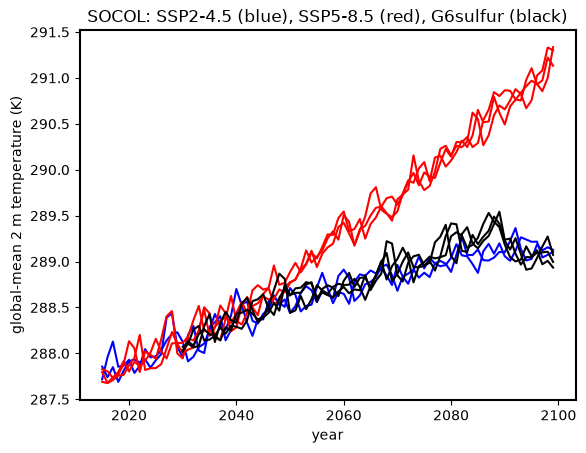

In [4]:
fig1, ax1 = plt.subplots()
ax1.plot(time1, ta_ssp2y, "b")
ax1.plot(time1, ta_ssp5y, "r")
ax1.plot(time2, ta_g6y, "k")
ax1.set_xlabel("year")
ax1.set_ylabel("global-mean 2 m temperature (K)")
ax1.set_title("SOCOL: SSP2-4.5 (blue), SSP5-8.5 (red), G6sulfur (black)")
for s in ax1.spines.values():
    s.set_linewidth(1.5)
fig1.set_facecolor("w")
plt.show()

Assemble `x_glob_m_save_SOCOL` (4 × 85): row 4 = SSP2-4.5 ensemble mean, row 3
= SSP5-8.5 ensemble mean, row 1 = G6sulfur mean placed at years 16:85
(2030–2099). Rows are MATLAB 1-based; here index 3, 2 and 0.

In [5]:
x_glob_m_save_SOCOL = np.full((4, ta_ssp2y.shape[0]), np.nan)
x_glob_m_save_SOCOL[3, :] = np.mean(ta_ssp2y, axis=1)
x_glob_m_save_SOCOL[2, :] = np.mean(ta_ssp5y, axis=1)
x_glob_m_save_SOCOL[0, 15:85] = np.mean(ta_g6y, axis=1)   # MATLAB 16:85

mu.save_npz("tas_timeseries_SOCOL", x_glob_m_save_SOCOL=x_glob_m_save_SOCOL)

'data_py/tas_timeseries_SOCOL.npz'

## End-of-century map (G6sulfur − SSP2-4.5)
G6sulfur months 601:840 are the last 20 years (2080–2099); SSP2-4.5 months
781:1020 are the same calendar window. Average over months and members, then
difference. `lat` is flipped (north-to-south → south-to-north) for the map,
matching the MATLAB `flip(lat)`.

<Figure size 900x500 with 0 Axes>

/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


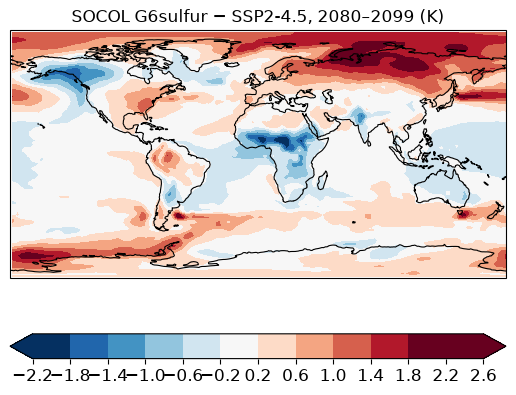

In [6]:
l_colb = 11
fc = brewermap(l_colb, "*RdBu")
mmin, mmax = -2.2, 2.2
v = np.arange(mmin, mmax + (mmax - mmin) / l_colb, (mmax - mmin) / l_colb)
v2 = np.arange(mmin, mmax + (mmax - mmin) / l_colb, (mmax - mmin) / l_colb)

lat_SOCOL = np.flip(lat_SOCOL)
lat = np.flip(lat)

# MATLAB slices 601:840 (->600:840) and 781:1020 (->780:1020)
g6_map = np.squeeze(np.mean(np.mean(ta_g6[:, :, 600:840, :], axis=2), axis=2))
ssp2_map = np.squeeze(np.mean(np.mean(ta_ssp2[:, :, 780:1020, :], axis=2), axis=2))
ssp5_map = np.squeeze(np.mean(np.mean(ta_ssp5[:, :, 780:1020, :], axis=2), axis=2))

# difference field for the map: fliplr(g6 - ssp2) transposed (lat, lon)
diff_map = np.fliplr(g6_map - ssp2_map).T

fig2 = plt.figure(figsize=(9, 5))
ax2 = mu.worldmap(figsize=None)
fig2 = ax2.figure
m = mu.contourfm(ax2, lat, lon, diff_map, v, cmap=fc)
m.set_clim(mmin, mmax)
mu.geoshow_coastlines(ax2)
cb = fig2.colorbar(m, ax=ax2, orientation="horizontal", ticks=v2)
cb.ax.tick_params(labelsize=12)
ax2.set_title("SOCOL G6sulfur − SSP2-4.5, 2080–2099 (K)")
fig2.set_facecolor("w")
plt.show()

Store the map cell array `x_map_20_SOCOL` (cells 1,3,4 in MATLAB → indices
0,2,3; cell 2/index 1 is left empty, mirroring the unassigned MATLAB cell).
The stored maps are `fliplr(mean...)` in (lon, lat) orientation (no transpose
— the transpose was only for plotting).

In [7]:
x_map_20_SOCOL = np.empty((1, 4), dtype=object)
for k in range(4):
    x_map_20_SOCOL[0, k] = np.zeros((0, 0))
x_map_20_SOCOL[0, 0] = np.fliplr(g6_map)
x_map_20_SOCOL[0, 3] = np.fliplr(ssp2_map)
x_map_20_SOCOL[0, 2] = np.fliplr(ssp5_map)

mu.save_npz("map_plots_GeoMIP_SOCOL",
            x_map_20_SOCOL=x_map_20_SOCOL,
            lat_SOCOL=lat_SOCOL, lon_SOCOL=lon_SOCOL)

'data_py/map_plots_GeoMIP_SOCOL.npz'

## Stratospheric AOD time series
Read the SOCOL AOD (`od525str`) for the three G6sulfur members and the
SSP5-8.5 reference. The MATLAB script reads `ssp51` three times for `aod_ssp5`
(members 2 and 3 reuse the `ssp51` file), which is reproduced faithfully.

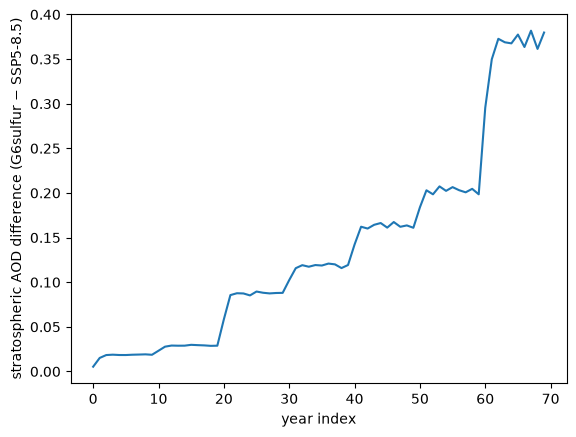

'data_py/aod_SOCOL.npz'

In [8]:
aod_g6 = stack(["SOCOL_AOD_440-625_g61_2030-2099.nc",
                "SOCOL_AOD_440-625_g62_2030-2099.nc",
                "SOCOL_AOD_440-625_g63_2030-2099.nc"], "od525str")
aod_ssp5 = stack(["SOCOL_AOD_440-625_ssp51_2030-2099.nc",
                  "SOCOL_AOD_440-625_ssp51_2030-2099.nc",
                  "SOCOL_AOD_440-625_ssp51_2030-2099.nc"], "od525str")

lat = mu.ncread(base + "socol4_s851_2m_temp_mm_2015-2099.nc", "lat")
ww = np.cos(lat / 180 * np.pi).ravel()

aod_g6s = glob_annual(aod_g6, 3)
aod_ssp5s = glob_annual(aod_ssp5, 3)

aod_SOCOL = (np.mean(aod_g6s, axis=1) - np.mean(aod_ssp5s, axis=1)).reshape(-1, 1)

fig3, ax3 = plt.subplots()
ax3.plot(aod_SOCOL)
ax3.set_xlabel("year index")
ax3.set_ylabel("stratospheric AOD difference (G6sulfur − SSP5-8.5)")
fig3.set_facecolor("w")
plt.show()

mu.save_npz("aod_SOCOL", aod_SOCOL=aod_SOCOL)

## Verification against the reference `.mat` files

In [9]:
def cmp_arr(name, a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    if a.shape != b.shape:
        print(f"  SHAPE MISMATCH {name}: py={a.shape} ref={b.shape}")
        return False, np.inf
    d = np.nanmax(np.abs(a - b)) if a.size else 0.0
    print(f"  {name}: shape {a.shape}, max|Δ| = {d:.3e}")
    return True, d


print("== tas_timeseries_SOCOL ==")
ref = mu.loadmat("tas_timeseries_SOCOL.mat")
ok1, d1 = cmp_arr("x_glob_m_save_SOCOL",
                  x_glob_m_save_SOCOL, ref["x_glob_m_save_SOCOL"])

print("== map_plots_GeoMIP_SOCOL ==")
ref = mu.loadmat("map_plots_GeoMIP_SOCOL.mat")
ok2 = True
dmax2 = 0.0
xm_r = ref["x_map_20_SOCOL"]
for k in range(4):
    a = np.asarray(x_map_20_SOCOL[0, k], dtype=float)
    b = np.asarray(xm_r[0, k], dtype=float)
    if a.size == 0 and b.size == 0:
        print(f"  x_map_20_SOCOL[{k}]: both empty")
        continue
    okk, dd = cmp_arr(f"x_map_20_SOCOL[{k}]", a, b)
    ok2 = ok2 and okk
    dmax2 = max(dmax2, dd)
for nm in ["lat_SOCOL", "lon_SOCOL"]:
    okk, dd = cmp_arr(nm, locals()[nm].ravel(), ref[nm].ravel())
    ok2 = ok2 and okk
    dmax2 = max(dmax2, dd)

print("== aod_SOCOL ==")
ref = mu.loadmat("aod_SOCOL.mat")
ok3, d3 = cmp_arr("aod_SOCOL", aod_SOCOL, ref["aod_SOCOL"])

# The reference map cells are stored as float32 (single, ~218–306 K), so a
# float32-eps round-off (~2e-4 on a 300 K field) is expected; the time series
# (float64) and the AOD difference match to ~1e-7. Tolerances are set
# accordingly — these are float-precision differences, not translation errors.
tol_ts = 1e-3      # tas_timeseries (float64 series, ~290 K)
tol_map = 1e-3     # map cells (reference stored as float32)
tol_aod = 1e-5     # aod difference (small magnitude)
pass1 = ok1 and d1 < tol_ts
pass2 = ok2 and dmax2 < tol_map
pass3 = ok3 and d3 < tol_aod
allok = pass1 and pass2 and pass3
print()
print("SUMMARY:",
      "tas_timeseries", "PASS" if pass1 else "FAIL",
      "| map_plots", "PASS" if pass2 else "FAIL",
      "| aod", "PASS" if pass3 else "FAIL")
assert allok, "verification failed"

== tas_timeseries_SOCOL ==
  x_glob_m_save_SOCOL: shape (4, 85), max|Δ| = 8.413e-05
== map_plots_GeoMIP_SOCOL ==
  x_map_20_SOCOL[0]: shape (192, 96), max|Δ| = 1.579e-04
  x_map_20_SOCOL[1]: both empty
  x_map_20_SOCOL[2]: shape (192, 96), max|Δ| = 1.513e-04
  x_map_20_SOCOL[3]: shape (192, 96), max|Δ| = 1.836e-04
  lat_SOCOL: shape (96,), max|Δ| = 0.000e+00
  lon_SOCOL: shape (192,), max|Δ| = 0.000e+00
== aod_SOCOL ==
  aod_SOCOL: shape (70, 1), max|Δ| = 3.636e-08

SUMMARY: tas_timeseries PASS | map_plots PASS | aod PASS
